# Исследование современных алгоритмов обрезания градиентов для моделей прогнозирования кликов

**Арсений Алёхин, ИУ6-74Б**

Сравнил десять методов обрезания градиентов и четыре контрольных режима на задаче прогноза клика.

In [1]:
import json
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.ticker import PercentFormatter

DATA = Path("data")
TABLES = json.loads((DATA / "experiments.json").read_text())

LABELS = {
    "none": "AdamW", "adam": "Adam", "global_norm": "Глобальная норма",
    "value": "По значению", "agc": "AGC", "adagc": "AdaGC",
    "autoclip": "AutoClip", "zclip": "ZClip", "softadaclip": "SoftAdaClip",
    "adamclip": "AdamClip", "adamwclip": "AdamWClip",
    "stableadamw": "StableAdamW", "spam": "SPAM", "stable_spam": "Stable-SPAM",
}
BLUE, TEAL, ORANGE, GRAY = "#234d78", "#007a72", "#bd5b28", "#7b8795"

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "semibold", "axes.spines.top": False,
    "axes.spines.right": False, "axes.labelcolor": "#223247",
    "text.color": "#18283a", "grid.color": "#dce4eb", "grid.linewidth": 0.7,
    "figure.facecolor": "white", "axes.facecolor": "white", "legend.frameon": False,
})


def read(name):
    return pd.DataFrame(TABLES[name])


def show_figure(fig, alt):
    preview = BytesIO()
    fig.savefig(preview, format="png", dpi=125, bbox_inches="tight", pad_inches=0.14)
    plt.close(fig)
    display(Image(data=preview.getvalue()), metadata={"image/png": {"alt": alt}})

## 1. Данные

Строка соответствует показу объявления. В таблице 1 означает клик, 0 означает показ без клика. Категории закодированы, время представлено через sin и cos. Поля о конверсии и атрибуции исключены.

Для статического теста использован [Criteo 1M](https://huggingface.co/datasets/eldieguinpo/criteo-1M). Для сравнения по дням использован [Criteo Attribution](https://huggingface.co/datasets/criteo/criteo-attribution-dataset).

In [2]:
examples = read("example").rename(columns={
    "day": "День", "label": "Клик", "campaign": "Корзина кампании",
    "cat1": "Категория 1", "cat3": "Категория 3",
    "relative_hour_sin": "sin времени", "relative_hour_cos": "cos времени",
})
display(examples.round(3))

split = read("static_split")
split["split"] = split["split"].map({
    "train": "Обучение", "validation": "Валидация", "test": "Тест",
})
split["ctr"] = 100 * split["ctr"]
display(split.rename(columns={"split": "Часть Criteo 1M", "rows": "Показы", "ctr": "CTR, %"})
        .set_index("Часть Criteo 1M").round(2))

,День,Клик,Корзина кампании,Категория 1,Категория 3,sin времени,cos времени
0,1,0,134,5831,4503,0.000,1.000
1,1,0,493,6180,7808,0.678,-0.736
2,1,1,489,5946,6745,-0.174,-0.985
3,1,0,4141,5946,5103,-0.874,-0.486
4,1,0,7612,5946,7317,-0.940,0.341
5,1,0,2378,5831,3269,-0.000,1.000


,Показы,"CTR, %"
Часть Criteo 1M,,
Обучение,800000,25.10
Валидация,100000,25.15
Тест,100000,25.25


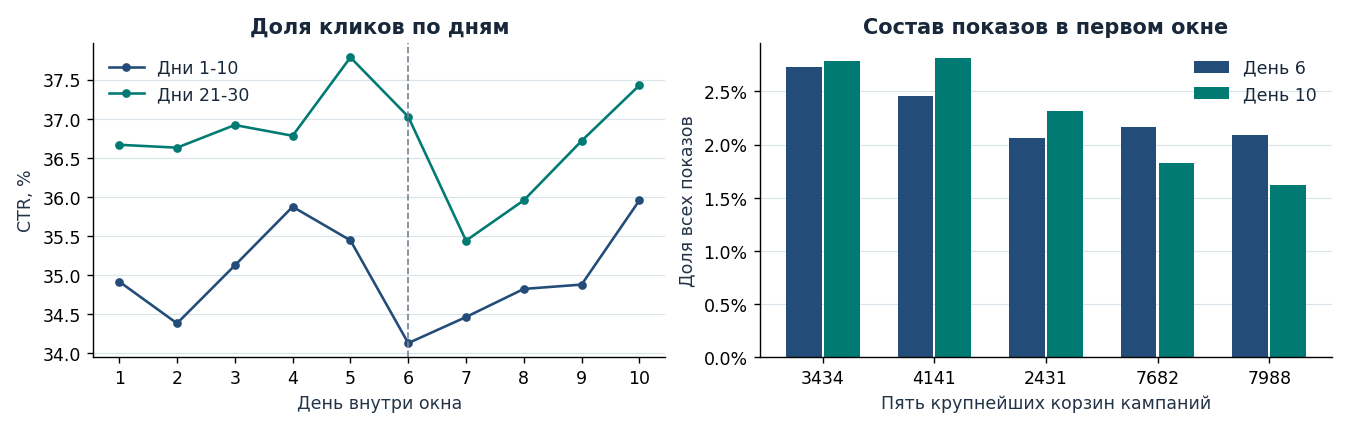

In [3]:
mix = read("campaign_mix").pivot(index="bucket", columns="day", values="share")
mix = mix.loc[mix.sum(axis=1).sort_values(ascending=False).index]
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.6, 3.25), layout="constrained")

for file, label, color in (("data_early", "Дни 1-10", BLUE),
                           ("data_late", "Дни 21-30", TEAL)):
    daily_data = read(file)
    local_day = daily_data.day - daily_data.day.iloc[0] + 1
    ax.plot(local_day, 100 * daily_data.ctr, marker="o", ms=4, color=color, label=label)
ax.axvline(6, color=GRAY, lw=1, ls="--")
ax.set(title="Доля кликов по дням", xlabel="День внутри окна", ylabel="CTR, %",
       xticks=range(1, 11))
ax.grid(axis="y")
ax.legend()

positions = np.arange(len(mix))
for day, offset, color in ((6, -0.17, BLUE), (10, 0.17, TEAL)):
    bx.bar(positions + offset, mix[day], width=0.32, color=color, label=f"День {day}")
bx.set(title="Состав показов в первом окне", xlabel="Пять крупнейших корзин кампаний",
       ylabel="Доля всех показов", xticks=positions, xticklabels=mix.index)
bx.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
bx.grid(axis="y")
bx.set_axisbelow(True)
bx.legend()
show_figure(fig, "CTR по дням в двух окнах и доли пяти корзин кампаний на шестой и десятый день.")

В каждом временном окне 3 млн показов. В первом окне CTR вырос с 34,13% на шестой день до 35,95% на десятый. За это время изменились и доли кампаний.

## 2. Модель и подбор порога

Категории подаются в MLP через эмбеддинги. В MLP четыре скрытых слоя на 256, 128, 64 и 32 нейрона. Вероятность клика получается из логита по формуле **p = sigmoid(z)**. Модель обучается по бинарной кросс-энтропии.

При глобальном обрезании градиент **g** масштабируется перед шагом AdamW. Если его норма выше порога **C**, новая норма равна **C**.

**g′ = g × min(1, C / ‖g‖₂)** при ‖g‖₂ > 0.

Ниже две модели обучаются по одной эпохе на Criteo Attribution. Для обучения взято 30 тыс. показов, для валидации 5 тыс.

In [4]:
from contextlib import redirect_stdout
from io import StringIO
from tempfile import TemporaryDirectory

from src.train import run

demo_config = {
    "data": str(DATA / "demo"),
    "seed": 42,
    "batch_size": 256,
    "epochs": 1,
    "embedding_dim": 8,
    "dropout": 0.1,
    "lr": 0.001,
    "weight_decay": 0.01,
    "warmup_steps": 20,
    "threads": 2,
    "evaluate_test": False,
}

rows = []
with TemporaryDirectory() as temporary:
    output = Path(temporary)
    for method, options in (("none", {}), ("global_norm", {"threshold": 0.1})):
        config = dict(demo_config, method=method, method_options=options)
        with redirect_stdout(StringIO()):
            run(config, output)
        metrics = json.loads((output / "metrics.json").read_text())
        validation = metrics["epochs"][-1]
        rows.append({
            "Режим": LABELS[method],
            "Шаги": metrics["steps"],
            "ROC-AUC на валидации": validation["auc"],
            "Кросс-энтропия на валидации": validation["logloss"],
        })

display(pd.DataFrame(rows).set_index("Режим").round(4))

,Шаги,ROC-AUC на валидации,Кросс-энтропия на валидации
Режим,,,
AdamW,118,0.6126,0.6267
Глобальная норма,118,0.6141,0.6262


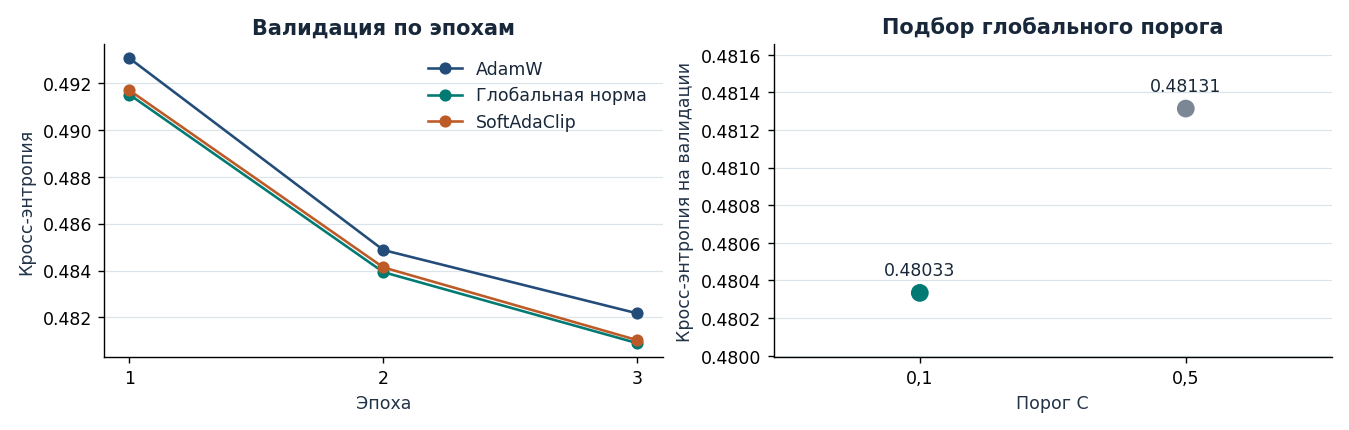

In [5]:
curves = read("validation_curves")
tuning = read("tuning")
thresholds = tuning[tuning.method.eq("global_norm")].copy()
thresholds["threshold"] = thresholds.options.map(lambda raw: json.loads(raw)["threshold"])
thresholds = thresholds.sort_values("threshold")
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.6, 3.25), layout="constrained")

for method, color in (("none", BLUE), ("global_norm", TEAL), ("softadaclip", ORANGE)):
    series = curves[curves.method.eq(method)].groupby("epoch").logloss.mean()
    ax.plot(series.index, series, marker="o", color=color, label=LABELS[method])
ax.set(title="Валидация по эпохам", xlabel="Эпоха", ylabel="Кросс-энтропия", xticks=[1, 2, 3])
ax.grid(axis="y")
ax.legend()

x = np.arange(len(thresholds))
bx.scatter(x, thresholds.val_logloss, s=85, zorder=3,
           c=[TEAL if selected else GRAY for selected in thresholds.selected])
for i, row in enumerate(thresholds.itertuples()):
    bx.annotate(f"{row.val_logloss:.5f}", (i, row.val_logloss), xytext=(0, 10),
                textcoords="offset points", ha="center")
bx.set(title="Подбор глобального порога", xlabel="Порог C", ylabel="Кросс-энтропия на валидации",
       xticks=x, xticklabels=[str(value).replace(".", ",") for value in thresholds.threshold],
       xlim=(-0.55, len(x) - 0.45))
bx.margins(y=0.35)
bx.grid(axis="y")
show_figure(fig, "Кросс-энтропия на валидации по эпохам и сравнение порогов 0,1 и 0,5.")

Порог выбирался по кросс-энтропии на валидации. Для глобальной нормы значение 0,1 дало 0,48033, значение 0,5 дало 0,48131. В итоговом тесте использован порог 0,1.

## 3. Сравнение на тесте

42 прогона на общем тесте из 100 тыс. показов. Точка показывает среднюю разность с контролем, отрезок показывает одно стандартное отклонение по трём инициализациям. AdamClip сравнивается с Adam, остальные методы сравниваются с AdamW.

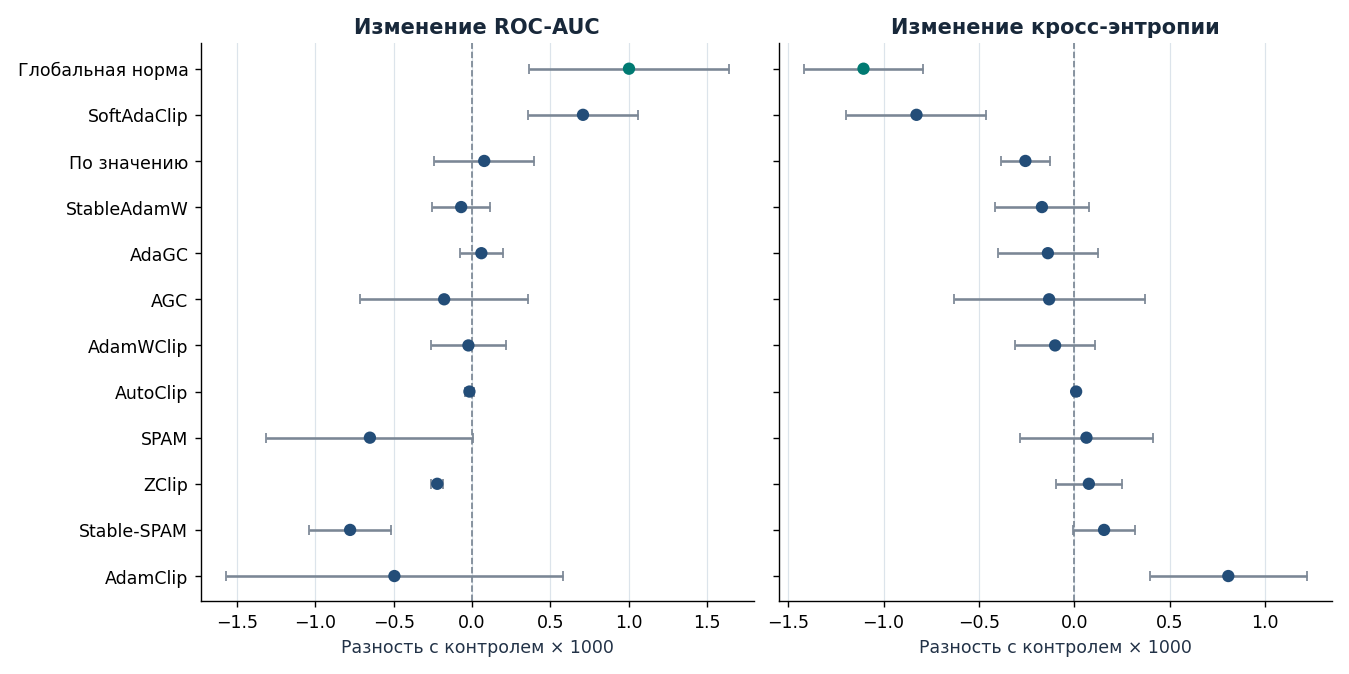

,ROC-AUC,Кросс-энтропия,Брайер,ECE
Режим,,,,
Глобальная норма,0.754017,0.484123,0.158276,0.009293
SoftAdaClip,0.753723,0.484401,0.158400,0.009843
По значению,0.753092,0.484971,0.158608,0.011225
StableAdamW,0.752944,0.485058,0.158652,0.011012
AdaGC,0.753074,0.485089,0.158661,0.012358
AGC,0.752836,0.485096,0.158665,0.010594
AdamWClip,0.752991,0.485127,0.158683,0.012412
AdamW,0.753013,0.485228,0.158729,0.013587
AutoClip,0.752997,0.485237,0.158733,0.013570


In [6]:
paired = read("paired")
order = (paired[paired.metric.eq("logloss")].groupby("method").delta.mean()
         .sort_values().index)
positions = np.arange(len(order))
fig, axes = plt.subplots(1, 2, figsize=(10.6, 5.2), sharey=True, layout="constrained")

for ax, metric, title in zip(
    axes, ("auc", "logloss"), ("Изменение ROC-AUC", "Изменение кросс-энтропии"),
):
    values = paired[paired.metric.eq(metric)].groupby("method").delta
    means = 1000 * values.mean().reindex(order)
    spread = 1000 * values.std().reindex(order)
    ax.axvline(0, color=GRAY, lw=1, ls="--")
    ax.errorbar(means, positions, xerr=spread, fmt="none", ecolor=GRAY, capsize=3)
    ax.scatter(means, positions, s=37, zorder=3,
               c=[TEAL if name == "global_norm" else BLUE for name in order])
    ax.set(title=title, xlabel="Разность с контролем × 1000")
    ax.grid(axis="x")
axes[0].set_yticks(positions, [LABELS[name] for name in order])
axes[0].invert_yaxis()
show_figure(fig, "Средние парные разности ROC-AUC и кросс-энтропии с разбросом по инициализациям.")

static = read("static")
mean_static = static.groupby("method")[["auc", "logloss", "brier", "ece"]].mean()
mean_static = mean_static.sort_values("logloss").rename(index=LABELS, columns={
    "auc": "ROC-AUC", "logloss": "Кросс-энтропия", "brier": "Брайер", "ece": "ECE",
})
display(mean_static.rename_axis("Режим").round(6))

С глобальным обрезанием ROC-AUC вырос с 0,7530 до 0,7540, кросс-энтропия снизилась с 0,4852 до 0,4841.

## 4. Калибровка

Прогнозы разбиты на 15 групп. В каждой группе сравниваются средняя вероятность клика и фактическая доля кликов. ECE учитывает размер группы. Температура для масштабирования логитов подбиралась на валидации.

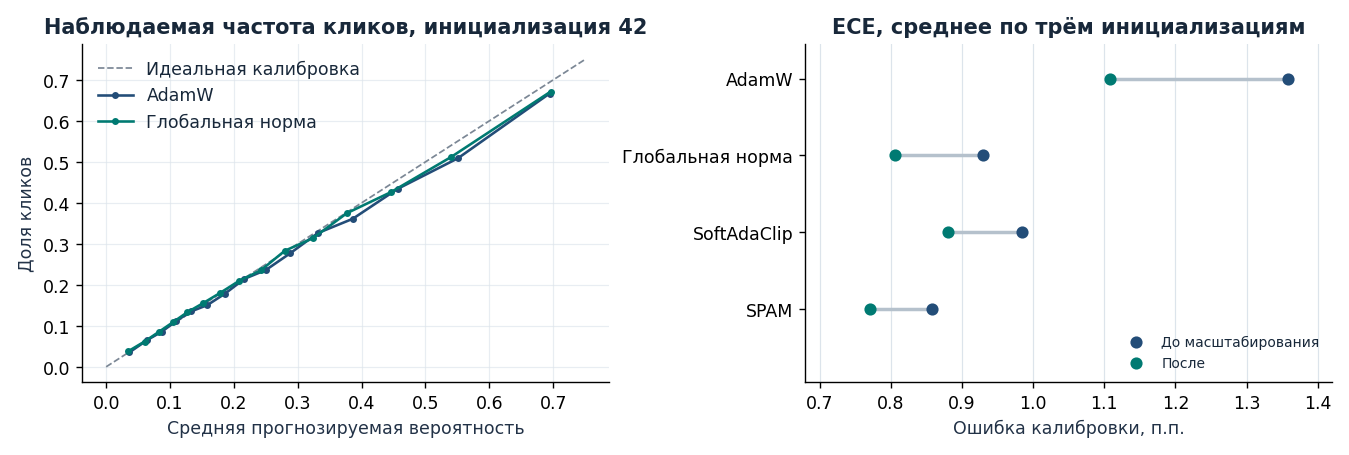

In [7]:
reliability = read("reliability")
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.6, 3.45), layout="constrained")
ax.plot([0, 0.75], [0, 0.75], color=GRAY, ls="--", lw=1, label="Идеальная калибровка")
for method, color in (("none", BLUE), ("global_norm", TEAL)):
    part = reliability[reliability.method.eq(method)]
    ax.plot(part.mean_prediction, part.observed_ctr, marker="o", ms=3, color=color,
            label=LABELS[method])
ax.set(title="Наблюдаемая частота кликов, инициализация 42",
       xlabel="Средняя прогнозируемая вероятность", ylabel="Доля кликов")
ax.grid(alpha=0.65)
ax.legend()

selected = ["none", "global_norm", "softadaclip", "spam"]
ece = 100 * static.groupby("method")[["ece", "ece_scaled"]].mean().loc[selected]
for i, row in enumerate(ece.itertuples()):
    bx.plot([row.ece, row.ece_scaled], [i, i], color="#b5c1cc", lw=2)
bx.scatter(ece.ece, np.arange(len(ece)), label="До масштабирования", color=BLUE, zorder=3)
bx.scatter(ece.ece_scaled, np.arange(len(ece)), label="После", color=TEAL, zorder=3)
bx.set(title="ECE, среднее по трём инициализациям", xlabel="Ошибка калибровки, п.п.",
       yticks=np.arange(len(ece)), yticklabels=[LABELS[name] for name in selected],
       xlim=(0.68, 1.42), ylim=(3.95, -0.45))
bx.grid(axis="x")
bx.legend(loc="lower right", fontsize=8)
show_figure(fig, "Диаграмма калибровки двух моделей и средняя ECE до и после масштабирования.")

SPAM дал наименьшую среднюю ECE на статическом тесте. У глобальной нормы ниже кросс-энтропия. У AdamW масштабирование снизило ECE на статическом тесте, но увеличило её на будущих днях раннего окна.

## 5. Дообучение по дням

В каждом окне модель обучается на первых пяти днях, шестой день используется для валидации. На каждом следующем дне сначала считаются прогнозы, затем модель обновляется по меткам этого дня. Для измерения изменения прогнозов используются одни и те же показы из валидационной выборки.

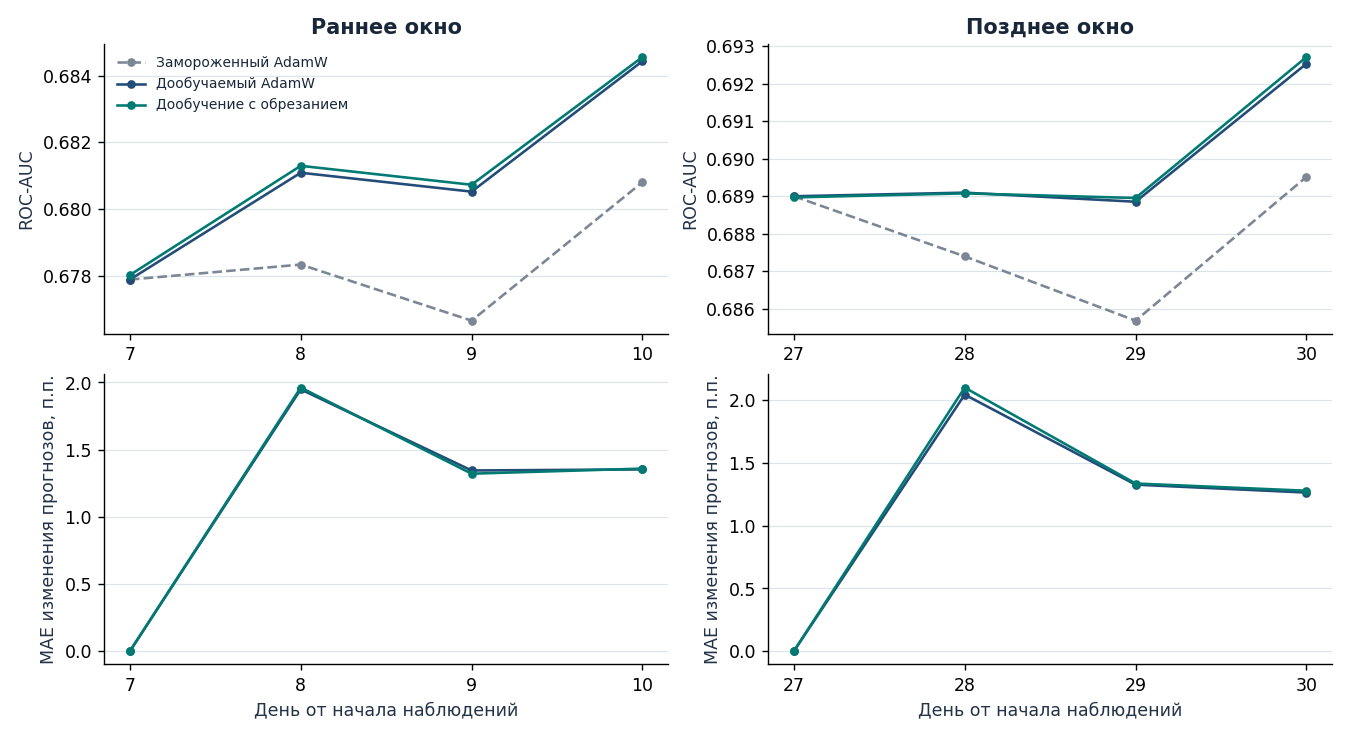

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.6, 5.7), layout="constrained")
variants = [
    ("none", "frozen", "Замороженный AdamW", GRAY, "--"),
    ("none", "updated", "Дообучаемый AdamW", BLUE, "-"),
    ("global_norm", "updated", "Дообучение с обрезанием", TEAL, "-"),
]
for i, (file, offset, title) in enumerate((
    ("daily_early", 1, "Раннее окно"),
    ("daily_late", 21, "Позднее окно"),
)):
    result = read(file)
    for method, variant, label, color, line in variants:
        daily = result[result.method.eq(method) & result.variant.eq(variant)]
        points = daily.groupby("day")[["auc", "drift_mae"]].mean()
        days = points.index + offset
        axes[0, i].plot(days, points.auc, color=color, ls=line, marker="o", ms=4, label=label)
        if variant == "updated":
            axes[1, i].plot(days, 100 * points.drift_mae, color=color, marker="o", ms=4)
    axes[0, i].set(title=title, ylabel="ROC-AUC")
    axes[1, i].set(xlabel="День от начала наблюдений", ylabel="MAE изменения прогнозов, п.п.")
    for ax in axes[:, i]:
        ax.set_xticks(np.arange(6, 10) + offset)
        ax.grid(axis="y")
axes[0, 0].legend(loc="upper left", fontsize=8)
show_figure(fig, "ROC-AUC с обновлением и заморозкой, а также изменение прогнозов в двух окнах.")

В обоих окнах дообучение повысило ROC-AUC относительно замороженного AdamW. Дополнительный прирост от глобального обрезания составил 0,00018 и 0,00009 соответственно. Изменение прогнозов у двух дообучаемых режимов близко.

## 6. Выбросы градиента

На пяти шагах градиент умножали на 50. Слева показано изменение нормы шага при первом выбросе. Справа точки показывают разность ROC-AUC с обычным запуском для каждой инициализации. Ромбы показывают среднее.

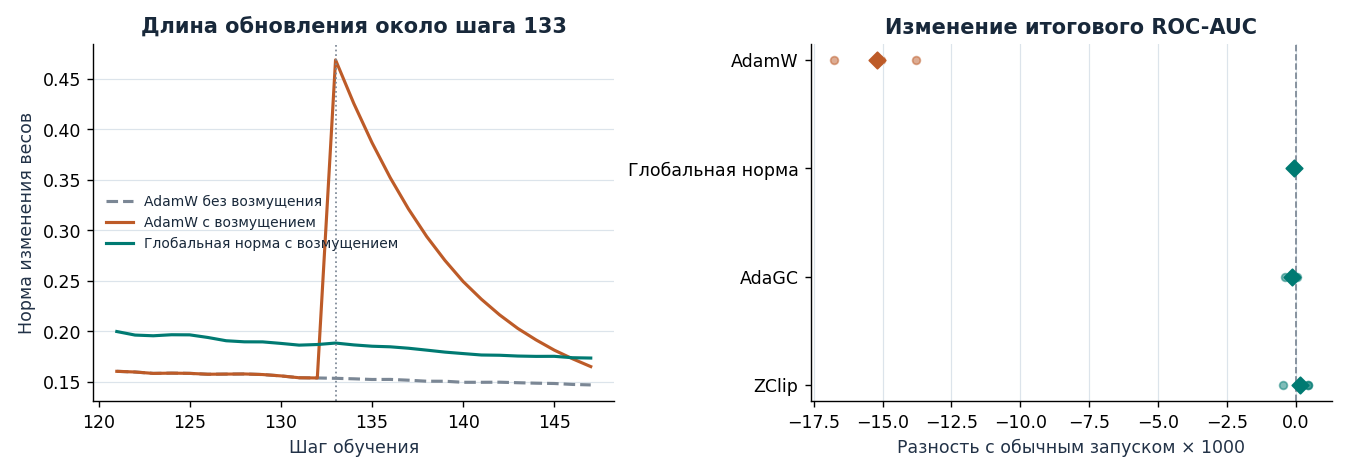

In [9]:
stress = read("stress")
steps = read("stress_steps")
event = steps.loc[steps.injected_spike.eq(1), "step"].min()
fig, (ax, bx) = plt.subplots(1, 2, figsize=(10.6, 3.6), layout="constrained")

for case, label, color, line in (
    ("clean", "AdamW без возмущения", GRAY, "--"),
    ("stress", "AdamW с возмущением", ORANGE, "-"),
    ("clipped", "Глобальная норма с возмущением", TEAL, "-"),
):
    part = steps[steps.case.eq(case)]
    ax.plot(part.step, part.update_norm, color=color, ls=line, lw=1.8, label=label)
ax.axvline(event, color=GRAY, lw=1, ls=":")
ax.set(title=f"Длина обновления около шага {event}",
       xlabel="Шаг обучения", ylabel="Норма изменения весов")
ax.grid(axis="y")
ax.legend(fontsize=8)

order = ["none", "global_norm", "adagc", "zclip"]
for i, name in enumerate(order):
    delta = 1000 * stress.loc[stress.method.eq(name), "delta_auc"]
    color = ORANGE if name == "none" else TEAL
    bx.scatter(delta, np.full(len(delta), i), s=20, alpha=0.5, color=color)
    bx.scatter(delta.mean(), i, s=45, marker="D", color=color, zorder=3)
bx.axvline(0, color=GRAY, lw=1, ls="--")
bx.set(title="Изменение итогового ROC-AUC", xlabel="Разность с обычным запуском × 1000",
       yticks=np.arange(len(order)), yticklabels=[LABELS[name] for name in order])
bx.invert_yaxis()
bx.grid(axis="x")
show_figure(fig, "Длина обновления у первого выброса и изменение ROC-AUC относительно обычного запуска.")

У AdamW ROC-AUC снизился в среднем на 0,0152. У глобального обрезания, AdaGC и ZClip модуль среднего изменения не превысил 0,00014.

## 7. Дополнительные сравнения

Сравнил шесть вариантов обрезания при одной инициализации. Отдельно проверил MLP и логистическую регрессию на одинаковых признаках при пяти эпохах.

In [10]:
variant_labels = {
    "adagc_listing": "AdaGC (порог по весам)", "adamclip_grad": "AdamClip (сырой градиент)",
    "agc_listing": "AGC (норма тензора)", "softadaclip_layer": "SoftAdaClip (послойный порог)",
    "stableadamw_listing": "StableAdamW (покомпонентное ограничение)", "zclip_listing": "ZClip (порог μ + kσ)",
}
variants_table = read("variants")[["method", "control", "control_auc", "observed_auc"]]
variants_table["method"] = variants_table.method.map(variant_labels)
variants_table["control"] = variants_table.control.map(LABELS)
display(variants_table.rename(columns={
    "method": "Вариант", "control": "С чем сравнивали",
    "control_auc": "ROC-AUC основного варианта", "observed_auc": "ROC-AUC проверки",
}).set_index("Вариант").round(4))

matched = pd.concat([
    read("longer").assign(architecture="MLP"),
    read("logistic").assign(architecture="Логистическая"),
])
matched["method"] = matched.method.map(LABELS)
display(matched.groupby(["architecture", "method"])[["auc", "logloss", "ece"]].mean()
        .rename_axis(["Архитектура, 5 эпох", "Режим"])
        .rename(columns={"auc": "ROC-AUC", "logloss": "Кросс-энтропия", "ece": "ECE"})
        .round(5))

,С чем сравнивали,ROC-AUC основного варианта,ROC-AUC проверки
Вариант,,,
AdaGC (порог по весам),AdaGC,0.7538,0.7540
AdamClip (сырой градиент),AdamWClip,0.7539,0.7458
AGC (норма тензора),AGC,0.7540,0.7537
SoftAdaClip (послойный порог),SoftAdaClip,0.7547,0.7541
StableAdamW (покомпонентное ограничение),StableAdamW,0.7538,0.5179
ZClip (порог μ + kσ),ZClip,0.7534,0.7539


ROC-AUC  Кросс-энтропия      ECE
Архитектура, 5 эпох Режим                                             
MLP                 AdaGC             0.76694         0.47579  0.01635
                    AdamW             0.76702         0.47563  0.01574
                    SPAM              0.76651         0.47619  0.01735
                    SoftAdaClip       0.76761         0.47529  0.01633
                    ZClip             0.76678         0.47595  0.01700
                    Глобальная норма  0.76737         0.47572  0.01732
Логистическая       AdamW             0.76543         0.47568  0.00388
                    Глобальная норма  0.76599         0.47525  0.00520

У варианта StableAdamW с покомпонентным ограничением ROC-AUC составил 0,5179, у основного варианта с RMS-масштабированием 0,7538. При пяти эпохах глобальное обрезание не снизило среднюю кросс-энтропию MLP.

## 8. Итог

Средняя разность ROC-AUC и стандартное отклонение по трём инициализациям. Для дообучения взяты три дня после первого обновления.

In [11]:
def daily_gain(file):
    table = read(file)
    table = table[table.method.eq("none") & table.day.gt(6)]
    comparison = table.pivot(index=["seed", "day"], columns="variant", values="auc")
    return (comparison.updated - comparison.frozen).groupby("seed").mean()


comparisons = [
    ("Статический тест", "Глобальная норма − AdamW",
     paired.loc[paired.method.eq("global_norm") & paired.metric.eq("auc"), "delta"]),
    ("Дообучение, раннее окно", "Обновляемый − замороженный AdamW", daily_gain("daily_early")),
    ("Дообучение, позднее окно", "Обновляемый − замороженный AdamW", daily_gain("daily_late")),
    ("Выбросы", "AdamW с выбросами − обычный AdamW", stress.loc[stress.method.eq("none"), "delta_auc"]),
    ("Выбросы", "Глобальная норма с выбросами − обычный запуск",
     stress.loc[stress.method.eq("global_norm"), "delta_auc"]),
]
display(pd.DataFrame([
    {"Режим": regime, "Сравнение": label,
     "ΔROC-AUC": f"{values.mean():+.5f} ± {values.std():.5f}"}
    for regime, label, values in comparisons
]).set_index("Режим"))

,Сравнение,ΔROC-AUC
Режим,,
Статический тест,Глобальная норма − AdamW,+0.00100 ± 0.00064
"Дообучение, раннее окно",Обновляемый − замороженный AdamW,+0.00342 ± 0.00018
"Дообучение, позднее окно",Обновляемый − замороженный AdamW,+0.00263 ± 0.00056
Выбросы,AdamW с выбросами − обычный AdamW,-0.01520 ± 0.00148
Выбросы,Глобальная норма с выбросами − обычный запуск,-0.00005 ± 0.00005


В обычном режиме выигрыш от обрезания небольшой. При выбросах глобальная норма, AdaGC и ZClip сохранили качество. На временных данных больший прирост дало само дообучение.